# Visual EDA and Simple Baselines

> Use quick plots and simple baselines to understand a dataset before fitting models.

**Track:** Machine Learning Roadmap · **Language:** English

## Learning goals
- Inspect distributions, relationships, and class balance.
- Plot a target and feature relationships before modeling.
- Establish what a simple benchmark can achieve.

Visual analysis can reveal errors such as impossible values, strong skew, class imbalance, and potential leakage candidates. A plot is a diagnostic—not proof of causality.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
df["target_name"] = df["target"].map({0: "malignant", 1: "benign"})
print(df.shape)
display(df.head())
print(df["target_name"].value_counts())

(569, 32)
target_name
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,target_name
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,malignant


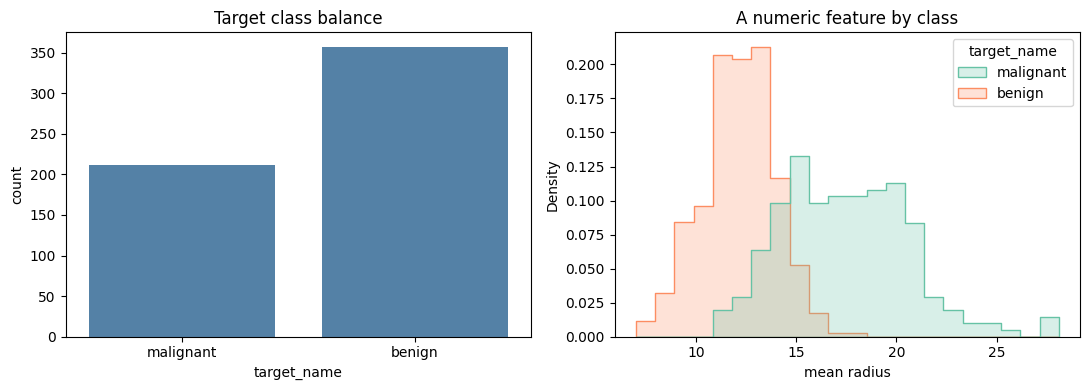

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="target_name", color="steelblue", ax=axes[0])
axes[0].set_title("Target class balance")
sns.histplot(data=df, x="mean radius", hue="target_name", palette="Set2", element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("A numeric feature by class")
plt.tight_layout()

## Correlation is a screening tool
Correlations can reveal redundant numeric features, but they do not measure all relationships and do not imply causation. Strong correlation can also arise from leakage or data collection practices.

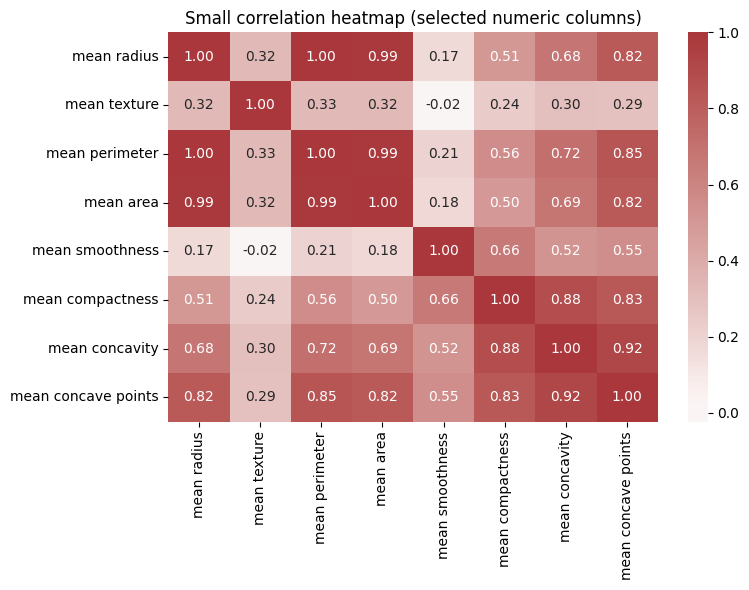

In [3]:
corr = df.select_dtypes("number").corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr.iloc[:8, :8], annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Small correlation heatmap (selected numeric columns)")
plt.tight_layout()

## Practice
1. Inspect a different feature distribution.
2. Find the percentage of each target class.
3. List one risk you would check before using a highly correlated feature.

In [4]:
print((df["target_name"].value_counts(normalize=True) * 100).round(1).astype(str) + "%")
print(df["worst area"].describe().round(2))
print("Check timing/availability and whether the feature was derived from the target or post-outcome data.")

target_name
benign       62.7%
malignant    37.3%
Name: proportion, dtype: object
count     569.00
mean      880.58
std       569.36
min       185.20
25%       515.30
50%       686.50
75%      1084.00
max      4254.00
Name: worst area, dtype: float64
Check timing/availability and whether the feature was derived from the target or post-outcome data.
